In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris


In [4]:
iris = load_iris()

df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = iris.target

In [37]:
display(df.head())
print("---------------------------------")
print("shape of the dataset is =",df.shape)
print("---------------------------------")
display(df.info())


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


---------------------------------
shape of the dataset is = (150, 5)
---------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


None

In [20]:
from sklearn.model_selection import train_test_split
x = iris.data
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state = 42)

print("Training samples ",len(X_train))
print("Testing samples",len(X_test))

Training samples  120
Testing samples 30


In [21]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
model = KNeighborsClassifier(n_neighbors=3)
model.fit(X_train,y_train)
y_pred =  model.predict(X_test)
accuracy = accuracy_score(y_test,y_pred)
print("Accuracy :",accuracy)


Accuracy : 1.0


In [22]:
from sklearn.metrics import (confusion_matrix,classification_report)
print("confusion :")
print(confusion_matrix(y_test,y_pred))

confusion :
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


In [23]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    mean_squared_error, mean_absolute_error, r2_score,
    silhouette_score
)


iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

df = pd.DataFrame(X, columns=feature_names)
df["species"] = [target_names[i] for i in y]

print("Dataset shape:", df.shape)
print(df.head())
print("\nSpecies counts:")
print(df["species"].value_counts())


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


def evaluate_classifier(name, model, X_test, y_test):
    predictions = model.predict(X_test)
    print(f"\n{name}")
    print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
    print("Precision (macro):",round(precision_score(y_test, predictions,average="macro", zero_division=0), 4))
    print("Recall (macro):",round(recall_score(y_test, predictions,average="macro", zero_division=0), 4))
    print("F1-score (macro):",round(f1_score(y_test, predictions,average="macro", zero_division=0), 4))
    print("\nConfusion matrix:\n",confusion_matrix(y_test, predictions))
    print("\nClassification report:\n",
          classification_report(
              y_test, predictions,
              target_names=target_names, zero_division=0
          ))
    return predictions


Dataset shape: (150, 5)
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

Species counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [24]:

from sklearn.linear_model import LinearRegression, Ridge, Lasso

X_reg = iris.data[:, [0, 1, 3]]
y_reg = iris.data[:, 2]

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

models_reg = {
    "Linear Regression": LinearRegression(),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso": make_pipeline(StandardScaler(), Lasso(alpha=0.1))
}

reg_results = {}

for name, model in models_reg.items():
    model.fit(Xr_train, yr_train)
    pred = model.predict(Xr_test)

    mse = mean_squared_error(yr_test, pred)
    reg_results[name] = {
        "MAE": mean_absolute_error(yr_test, pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(yr_test, pred)
    }

    print("\n", name)
    print("First 5 predictions:", np.round(pred[:5], 2))
    print("MAE:", round(reg_results[name]["MAE"], 3))
    print("RMSE:", round(reg_results[name]["RMSE"], 3))
    print("R2:", round(reg_results[name]["R2"], 3))

print("\nRegression comparison:")
print(pd.DataFrame(reg_results).T)



 Linear Regression
First 5 predictions: [4.13 1.88 7.03 4.43 4.93]
MAE: 0.261
RMSE: 0.361
R2: 0.96

 Ridge
First 5 predictions: [4.13 1.9  7.02 4.43 4.93]
MAE: 0.26
RMSE: 0.359
R2: 0.961

 Lasso
First 5 predictions: [4.03 2.03 6.71 4.38 4.75]
MAE: 0.28
RMSE: 0.373
R2: 0.957

Regression comparison:
                        MAE       MSE      RMSE        R2
Linear Regression  0.260518  0.130016  0.360578  0.960329
Ridge              0.259851  0.129072  0.359265  0.960618
Lasso              0.280436  0.139493  0.373487  0.957438



 Gini

Gini
Accuracy: 0.9333
Precision (macro): 0.9333
Recall (macro): 0.9333
F1-score (macro): 0.9333

Confusion matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Classification report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


 Entropy

Entropy
Accuracy: 0.9333
Precision (macro): 0.9333
Recall (macro): 0.9333
F1-score (macro): 0.9333

Confusion matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Classification report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy           

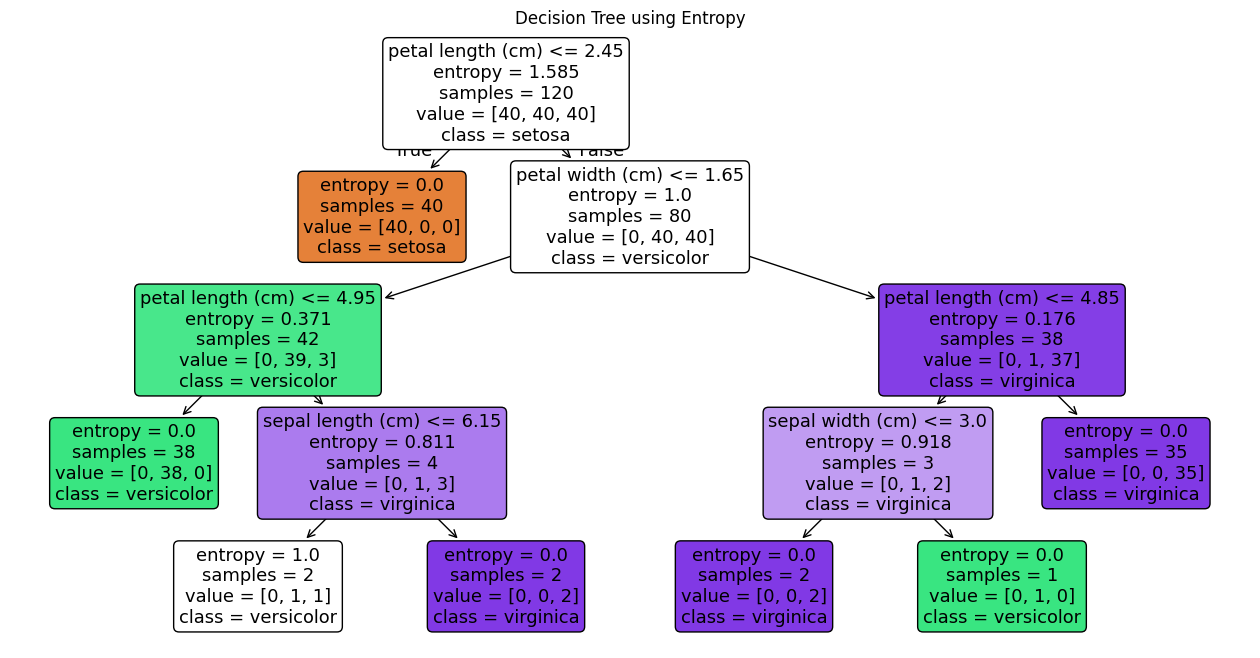

Feature importance:
petal length (cm)    0.671954
petal width (cm)     0.306791
sepal width (cm)     0.014638
sepal length (cm)    0.006616
dtype: float64


In [25]:

from sklearn.tree import DecisionTreeClassifier, plot_tree

tree_models = {
    "Gini": DecisionTreeClassifier(
        criterion="gini", max_depth=4, random_state=42
    ),
    "Entropy": DecisionTreeClassifier(
        criterion="entropy", max_depth=4, random_state=42
    ),
    "Log Loss": DecisionTreeClassifier(
        criterion="log_loss", max_depth=4, random_state=42
    )
}

for name, model in tree_models.items():
    model.fit(X_train, y_train)
    print("\n", name)
    evaluate_classifier(name, model, X_test, y_test)

plt.figure(figsize=(16, 8))
plot_tree(
    tree_models["Entropy"],
    feature_names=feature_names,
    class_names=target_names,
    filled=True,
    rounded=True
)
plt.title("Decision Tree using Entropy")
plt.show()

print("Feature importance:")
print(pd.Series(
    tree_models["Entropy"].feature_importances_,
    index=feature_names
).sort_values(ascending=False))



Logistic L2 (Ridge)
Accuracy: 0.9333
Precision (macro): 0.9333
Recall (macro): 0.9333
F1-score (macro): 0.9333

Confusion matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Classification report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Logistic L1 (Lasso)
Accuracy: 0.9333
Precision (macro): 0.9333
Recall (macro): 0.9333
F1-score (macro): 0.9333

Confusion matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Classification report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy 

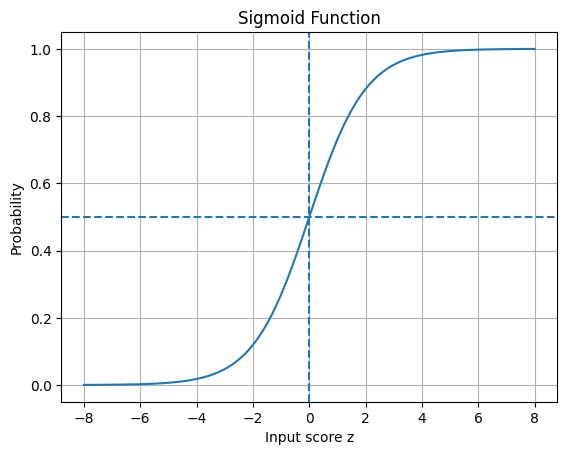

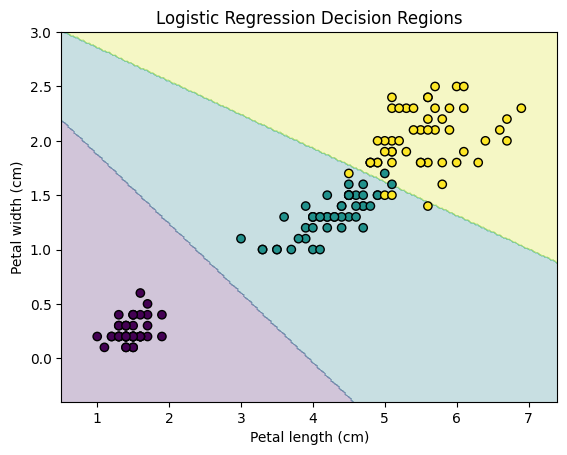

In [26]:

from sklearn.linear_model import LogisticRegression

log_models = {
    "Logistic L2 (Ridge)": make_pipeline(
        StandardScaler(),
        LogisticRegression(C=1.0, penalty="l2", max_iter=2000)
    ),
    "Logistic L1 (Lasso)": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=1.0, penalty="l1", solver="saga",
            max_iter=5000, random_state=42
        )
    )
}

for name, model in log_models.items():
    model.fit(X_train, y_train)
    evaluate_classifier(name, model, X_test, y_test)

# demonstrate the sigmoid function
z = np.linspace(-8, 8, 200)
sigmoid = 1 / (1 + np.exp(-z))

plt.plot(z, sigmoid)
plt.axhline(0.5, linestyle="--")
plt.axvline(0, linestyle="--")
plt.xlabel("Input score z")
plt.ylabel("Probability")
plt.title("Sigmoid Function")
plt.grid(True)
plt.show()

# Decision boundary using two features
X2 = iris.data[:, [2, 3]]  # Petal length and width
y2 = iris.target

boundary_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)
boundary_model.fit(X2, y2)

x_min, x_max = X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5
y_min, y_max = X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)
grid = np.c_[xx.ravel(), yy.ravel()]
Z = boundary_model.predict(grid).reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.25, cmap="viridis")
plt.scatter(X2[:, 0], X2[:, 1], c=y2, cmap="viridis",
            edgecolor="black")
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Logistic Regression Decision Regions")
plt.show()


In [27]:

from sklearn.neighbors import KNeighborsClassifier

knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=3)
)

knn.fit(X_train, y_train)
knn_predictions = evaluate_classifier(
    "KNN (K=3)", knn, X_test, y_test
)

sample = X_test[0].reshape(1, -1)
prediction = knn.predict(sample)[0]

print("Measurements:", sample[0])
print("Predicted species:", target_names[prediction])
print("Actual species:", target_names[y_test[0]])



KNN (K=3)
Accuracy: 0.9333
Precision (macro): 0.9444
Recall (macro): 0.9333
F1-score (macro): 0.9327

Confusion matrix:
 [[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Classification report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30

Measurements: [4.4 3.  1.3 0.2]
Predicted species: setosa
Actual species: setosa


In [28]:

from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train, y_train)

nb_predictions = evaluate_classifier(
    "Gaussian Naive Bayes", nb, X_test, y_test
)

# Show predicted class probabilities
print("Probabilities for first 5 test flowers:")
print(np.round(nb.predict_proba(X_test[:5]), 3))



Gaussian Naive Bayes
Accuracy: 0.9667
Precision (macro): 0.9697
Recall (macro): 0.9667
F1-score (macro): 0.9666

Confusion matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Probabilities for first 5 test flowers:
[[1.    0.    0.   ]
 [0.    0.088 0.912]
 [0.    1.    0.   ]
 [0.    1.    0.   ]
 [1.    0.    0.   ]]


2 question


Euclidean distances between first 5 flowers:
[[0.   1.18 0.85 1.1  0.26]
 [1.18 0.   0.52 0.43 1.39]
 [0.85 0.52 0.   0.28 0.99]
 [1.1  0.43 0.28 0.   1.25]
 [0.26 1.39 0.99 1.25 0.  ]]

K-means cluster counts:
0    53
1    50
2    47
Name: count, dtype: int64
Silhouette score: 0.46


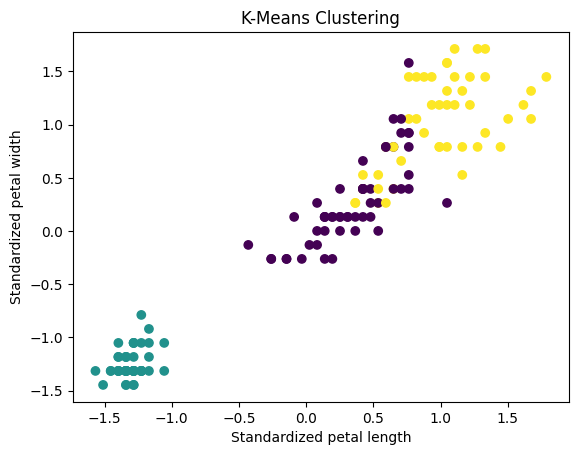


Hierarchical cluster counts:
0    71
1    49
2    30
Name: count, dtype: int64
Silhouette score: 0.447


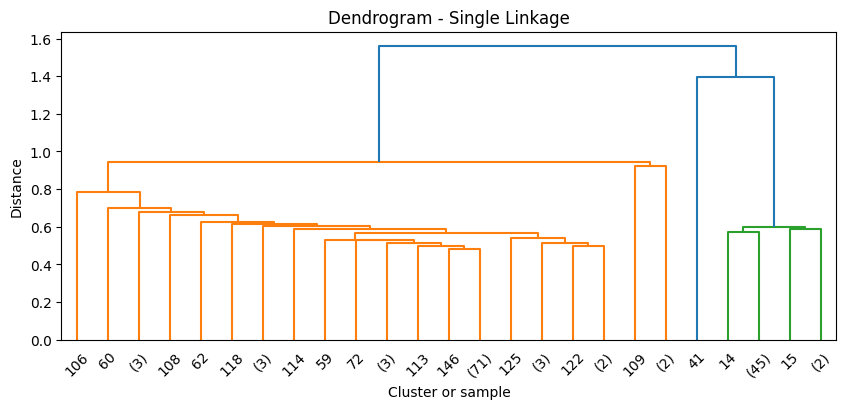

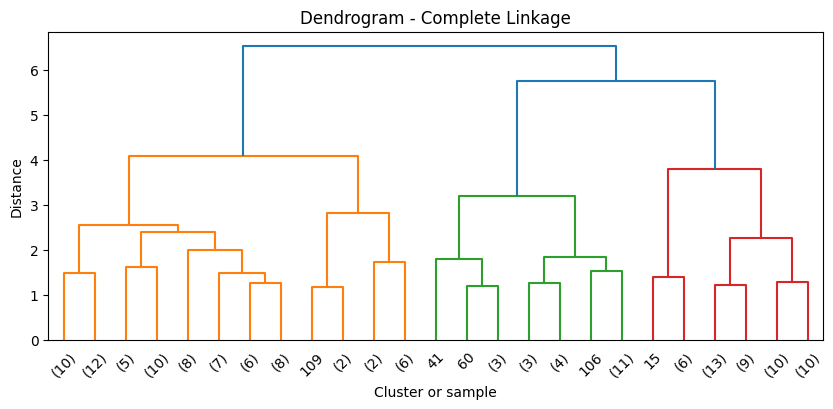

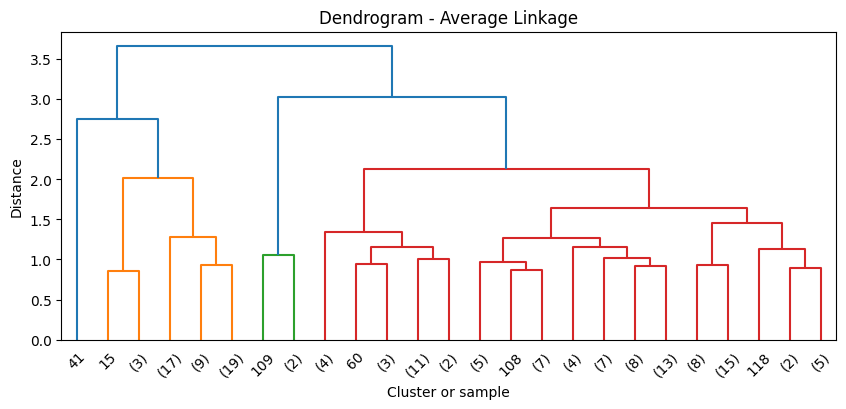

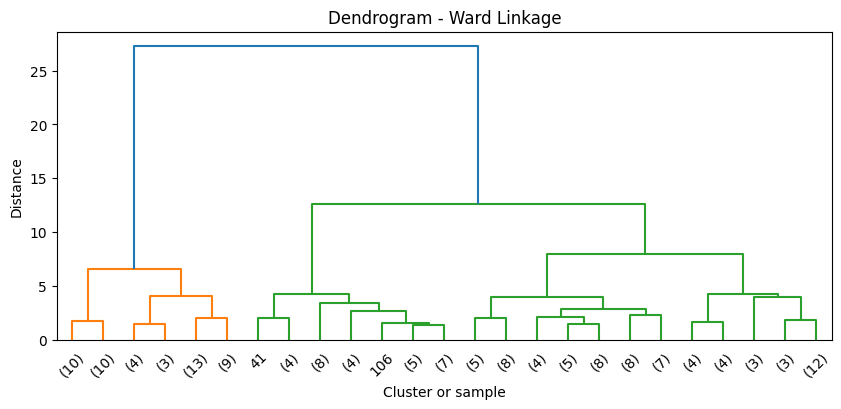

In [29]:

from sklearn.metrics import pairwise_distances
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Euclidean distances between first 5 flowers:")
print(np.round(pairwise_distances(X_scaled[:5]), 2))

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("\nK-means cluster counts:")
print(pd.Series(kmeans_labels).value_counts().sort_index())
print("Silhouette score:",
      round(silhouette_score(X_scaled, kmeans_labels), 3))

plt.scatter(X_scaled[:, 2], X_scaled[:, 3],
            c=kmeans_labels, cmap="viridis")
plt.xlabel("Standardized petal length")
plt.ylabel("Standardized petal width")
plt.title("K-Means Clustering")
plt.show()

hierarchical = AgglomerativeClustering(
    n_clusters=3, linkage="ward"
)
hier_labels = hierarchical.fit_predict(X_scaled)

print("\nHierarchical cluster counts:")
print(pd.Series(hier_labels).value_counts().sort_index())
print("Silhouette score:",
      round(silhouette_score(X_scaled, hier_labels), 3))

for method in ["single", "complete", "average", "ward"]:
    Z_link = linkage(X_scaled, method=method)
    plt.figure(figsize=(10, 4))
    dendrogram(Z_link, truncate_mode="lastp", p=25)
    plt.title(f"Dendrogram - {method.title()} Linkage")
    plt.xlabel("Cluster or sample")
    plt.ylabel("Distance")
    plt.show()



 Bagging
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


 Random Forest
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30


 AdaBoost
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90     

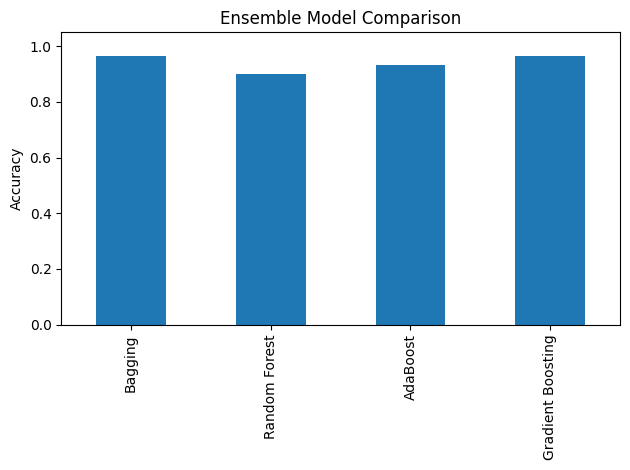

In [30]:

from sklearn.ensemble import (
    RandomForestClassifier,
    BaggingClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)
from sklearn.tree import DecisionTreeClassifier

ensemble_models = {
    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=3),
        n_estimators=100,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    "AdaBoost": AdaBoostClassifier(
        n_estimators=50, random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, random_state=42
    )
}

ensemble_results = {}

for name, model in ensemble_models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    ensemble_results[name] = {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, average="macro",
            zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, average="macro",
            zero_division=0
        )
    }
    print("\n", name)
    print(classification_report(
        y_test, predictions,
        target_names=target_names, zero_division=0
    ))

ensemble_df = pd.DataFrame(ensemble_results).T
print("\nEnsemble comparison:")
print(ensemble_df.round(3))

ensemble_df["Accuracy"].plot(
    kind="bar", ylim=(0, 1.05), ylabel="Accuracy",
    title="Ensemble Model Comparison"
)
plt.tight_layout()
plt.show()


Cluster counts:
0    45
1    50
2    55
Name: count, dtype: int64
Silhouette score: 0.374
BIC: 801.55
AIC: 669.08

Cluster probabilities for first 5 flowers:
[[0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]]


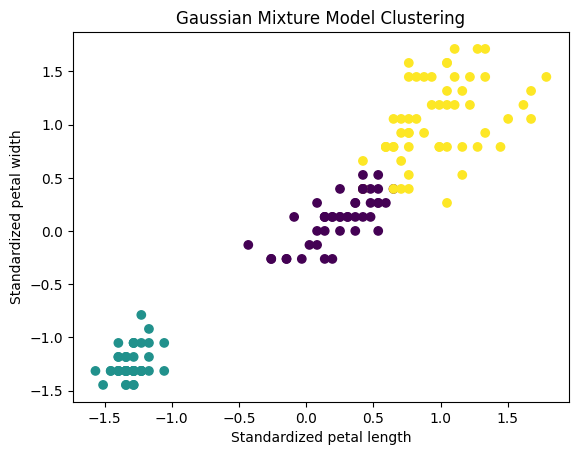

In [31]:

from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(
    n_components=3, covariance_type="full",
    random_state=42, n_init=5
)

gmm_labels = gmm.fit_predict(X_scaled)
gmm_probabilities = gmm.predict_proba(X_scaled)

print("Cluster counts:")
print(pd.Series(gmm_labels).value_counts().sort_index())

print("Silhouette score:",
      round(silhouette_score(X_scaled, gmm_labels), 3))
print("BIC:", round(gmm.bic(X_scaled), 2))
print("AIC:", round(gmm.aic(X_scaled), 2))

print("\nCluster probabilities for first 5 flowers:")
print(np.round(gmm_probabilities[:5], 3))

plt.scatter(
    X_scaled[:, 2], X_scaled[:, 3],
    c=gmm_labels, cmap="viridis"
)
plt.xlabel("Standardized petal length")
plt.ylabel("Standardized petal width")
plt.title("Gaussian Mixture Model Clustering")
plt.show()


Original shape: (150, 4)
Reduced shape: (150, 2)
Explained variance ratio: [0.73  0.229]
Total variance retained: 95.81 %


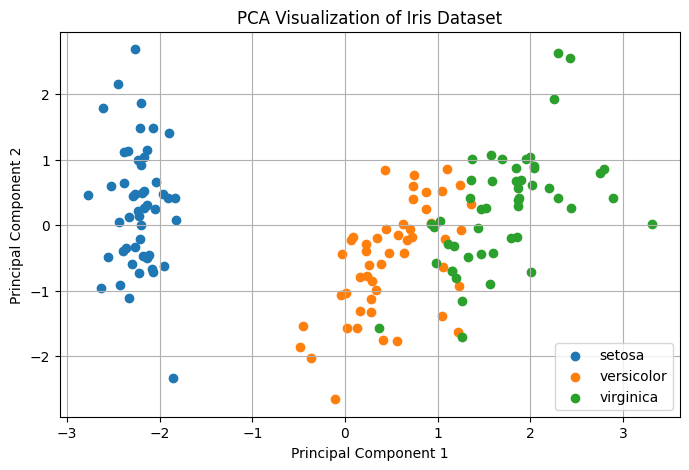

In [32]:

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Original shape:", X_scaled.shape)
print("Reduced shape:", X_pca.shape)
print("Explained variance ratio:",
      np.round(pca.explained_variance_ratio_, 3))
print("Total variance retained:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

# Plot PCA components
plt.figure(figsize=(8, 5))
for i, species in enumerate(target_names):
    plt.scatter(
        X_pca[y == i, 0], X_pca[y == i, 1],
        label=species
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Iris Dataset")
plt.legend()
plt.grid(True)
plt.show()


3 Analyse the performance of the different models developed in question (1) and (2) using appropriate metrices.  

              Model  Accuracy  Precision  Recall  F1-score
        Naive Bayes     0.967      0.970   0.967     0.967
            Bagging     0.967      0.970   0.967     0.967
  Gradient Boosting     0.967      0.970   0.967     0.967
      Decision Tree     0.933      0.933   0.933     0.933
           AdaBoost     0.933      0.933   0.933     0.933
Logistic Regression     0.933      0.933   0.933     0.933
                KNN     0.933      0.944   0.933     0.933
      Random Forest     0.900      0.902   0.900     0.900


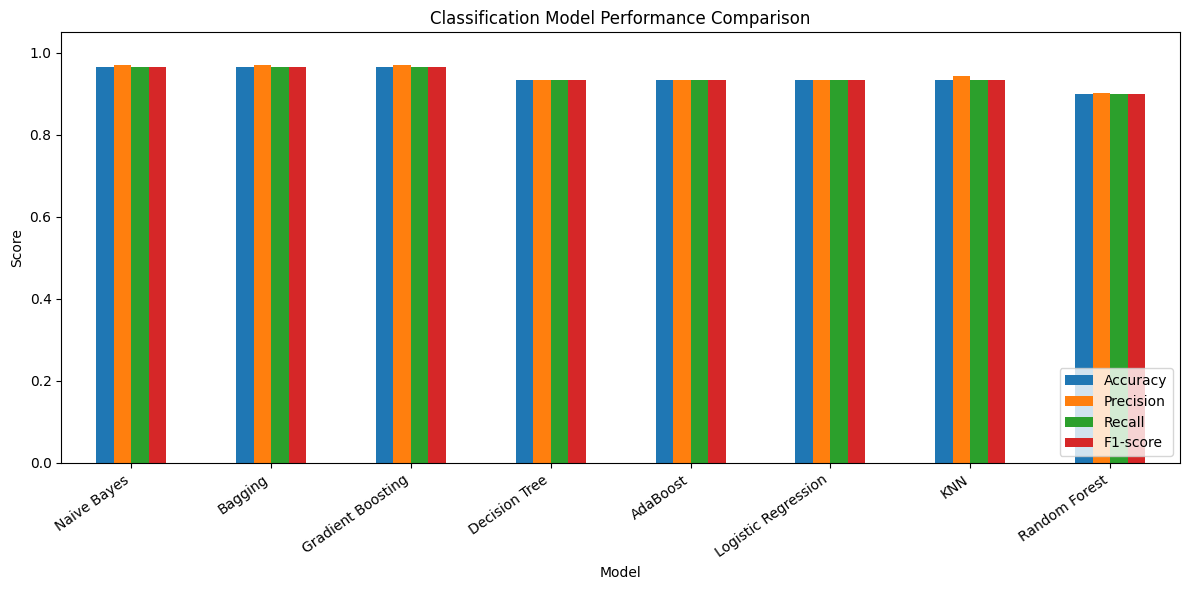


Best model by test F1-score: Naive Bayes

Confusion matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Detailed classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [33]:


all_models = { "Decision Tree": tree_models["Gini"],
    "Logistic Regression": log_models["Logistic L2 (Ridge)"],
    "KNN": knn,
    "Naive Bayes": nb,
    "Bagging": ensemble_models["Bagging"],
    "Random Forest": ensemble_models["Random Forest"],
    "AdaBoost": ensemble_models["AdaBoost"],
    "Gradient Boosting": ensemble_models["Gradient Boosting"]
}

comparison = []

for name, model in all_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, pred, average="macro", zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison)
comparison_df = comparison_df.sort_values(
    "F1-score", ascending=False
).reset_index(drop=True)

print(comparison_df.round(3).to_string(index=False))

comparison_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].plot(kind="bar", figsize=(12, 6), ylim=(0, 1.05))

plt.ylabel("Score")
plt.title("Classification Model Performance Comparison")
plt.xticks(rotation=35, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

best_name = comparison_df.loc[0, "Model"]
best_model = all_models[best_name]
best_predictions = best_model.predict(X_test)

print("\nBest model by test F1-score:", best_name)
print("\nConfusion matrix:")
print(confusion_matrix(y_test, best_predictions))

print("\nDetailed classification report:")
print(classification_report(
    y_test, best_predictions,
    target_names=target_names,
    zero_division=0
))
